# Análisis exploratorio y evaluación — Sentiment140

Notebook de apoyo para el informe y la presentación. **No reemplaza al pipeline**: importa el código
de `src/` (preprocesamiento, modelos entrenados) para que todo use exactamente lo mismo que la app web.

Requisitos previos:
```bash
pip install -r requirements-notebook.txt
python -m src.train        # descarga el dataset si falta y entrena los 3 modelos
```

Contenido:
1. El dataset original (1.6 M tweets)
2. Preprocesamiento: antes y después
3. Vocabulario por clase
4. Evaluación de los modelos (Accuracy, F1, matriz de confusión)
5. Qué aprendió cada modelo
6. Generalización: test etiquetado a mano y percepción por marca
7. Conclusiones

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score, confusion_matrix

from src.config import COLUMNS, RAW_DIR, SAMPLE_PATH
from src.dataset import cargar_dataset
from src.preprocessing import limpiar_texto
from src.predict import cargar_artefactos

NEG, POS, ACENTO, TINTA = "#ff5c8a", "#39ffb0", "#3db8ff", "#9ad8ff"
plt.rcParams.update({
    "figure.facecolor": "#06111f", "axes.facecolor": "#0d2744", "savefig.facecolor": "#06111f",
    "axes.edgecolor": "#1f4a75", "axes.labelcolor": TINTA, "text.color": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "axes.grid": True, "grid.color": "#1f4a75",
    "grid.alpha": .5, "figure.dpi": 110, "axes.titleweight": "bold",
})

## 1. El dataset original

In [2]:
df = cargar_dataset()
df["fecha"] = pd.to_datetime(df["date"].str.replace(" PDT", "", regex=False), format="%a %b %d %H:%M:%S %Y")
print(f"{len(df):,} tweets · {df['user'].nunique():,} usuarios · {df['fecha'].min():%Y-%m-%d} → {df['fecha'].max():%Y-%m-%d}")
print("Valores de 'flag':", df["flag"].unique())
df[["target", "date", "user", "text"]].head()

Dataset ya presente: /home/grim/Documents/projects/ProyectoFinal_Mineria/data/raw/training.1600000.processed.noemoticon.csv


1,600,000 tweets · 659,775 usuarios · 2009-04-06 → 2009-06-25
Valores de 'flag': <StringArray>
['NO_QUERY']
Length: 1, dtype: str


,target,date,user,text
0,0,Mon Apr 06 22:19:45 PDT 2009,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,Mon Apr 06 22:19:49 PDT 2009,scotthamilton,is upset that he can't update his Facebook by ...
2,0,Mon Apr 06 22:19:53 PDT 2009,mattycus,@Kenichan I dived many times for the ball. Man...
3,0,Mon Apr 06 22:19:57 PDT 2009,ElleCTF,my whole body feels itchy and like its on fire
4,0,Mon Apr 06 22:19:57 PDT 2009,Karoli,"@nationwideclass no, it's not behaving at all...."


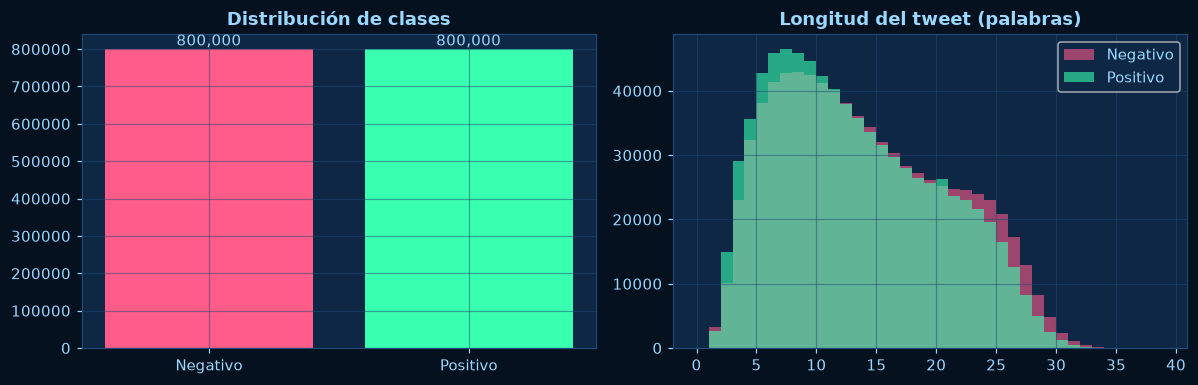

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
conteo = df["label"].map({0: "Negativo", 1: "Positivo"}).value_counts().sort_index()
ax[0].bar(conteo.index, conteo.values, color=[NEG, POS])
ax[0].set_title("Distribución de clases")
for i, v in enumerate(conteo.values):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")

df["n_palabras"] = df["text"].str.split().str.len()
for lab, col in [(0, NEG), (1, POS)]:
    ax[1].hist(df.loc[df.label == lab, "n_palabras"], bins=range(0, 40), alpha=.6, color=col,
               label="Negativo" if lab == 0 else "Positivo")
ax[1].set_title("Longitud del tweet (palabras)"); ax[1].legend()
plt.tight_layout(); plt.show()

El dataset está **perfectamente balanceado** (800 000 por clase) y los tweets son cortos (≈13 palabras).
Las etiquetas no son manuales: los autores las asignaron por **supervisión distante** usando emoticonos
(`:)` → positivo, `:(` → negativo) y luego quitaron los emoticonos del texto. Por eso el techo realista
de accuracy con modelos clásicos ronda el 75–80 %.

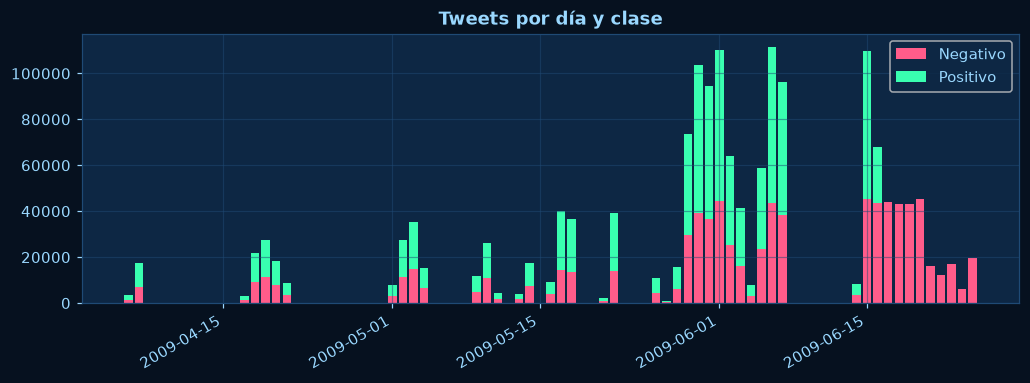

In [4]:
por_dia = df.groupby([df["fecha"].dt.date, "label"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(por_dia.index, por_dia[0], color=NEG, label="Negativo")
ax.bar(por_dia.index, por_dia[1], bottom=por_dia[0], color=POS, label="Positivo")
ax.set_title("Tweets por día y clase"); ax.legend(); fig.autofmt_xdate(); plt.show()

**Hallazgo importante para el análisis temporal:** la recolección no es uniforme. Hay muchos días sin datos
y, **desde el 17 de junio, el 100 % de los tweets son negativos** (antes la proporción ronda 58–64 % positivos). Es un **sesgo de muestreo** del
dataset, no un cambio real de opinión, y conviene mencionarlo cuando se interpreten tendencias temporales.

## 2. Preprocesamiento: antes y después

In [5]:
ejemplos = df.sample(6, random_state=7)[["text"]].copy()
ejemplos["texto_limpio"] = ejemplos["text"].map(limpiar_texto)
pd.set_option("display.max_colwidth", 90)
ejemplos

,text,texto_limpio
709290,feelin down lately but i've no reason too,feelin down lately but i ve no reason too
654075,"With ju, clare, elly and zoe about to leave marbella",with ju clare elly and zoe about to leave marbella
728623,Wish I couldve seen Miley and nick sing 2night.,wish i couldve seen miley and nick sing 2night
697650,"Had to work today. 1 hour down, 6 to go.",had to work today 1 hour down 6 to go
1244425,Just started to catch up on House viewing. Kind of odd as I was watched blackadder the...,just started to catch up on house viewing kind of odd as i was watched blackadder the ...
471810,"@_SandBox yeah I've already applied for a couple, one that I REALLY want, so just got...",yeah i ve already applied for a couple one that i really want so just got to keep my f...


`limpiar_texto` pasa a minúsculas, elimina URLs y `@menciones`, convierte `#hashtag` → `hashtag` y quita
signos, y expande las contracciones negativas (`can't` → `can not`). Después, `TfidfVectorizer` elimina
*stop words* en inglés **excepto las negaciones**, descarta términos que aparecen en menos de
2 tweets y genera unigramas + bigramas (máx. 5 000 features).

## 3. Vocabulario por clase

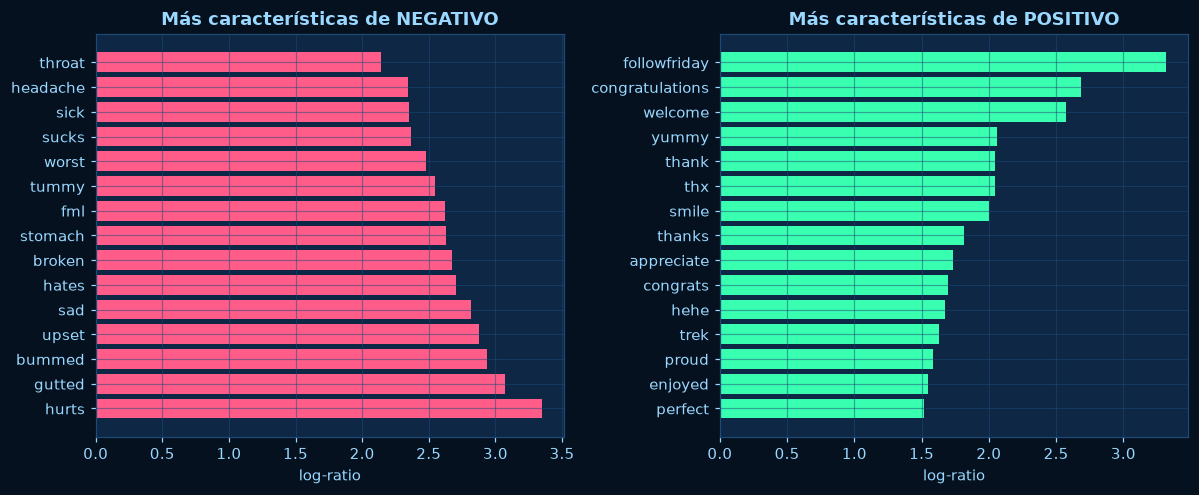

In [6]:
muestra = pd.read_csv(SAMPLE_PATH).fillna({"texto_limpio": ""})
cv = CountVectorizer(stop_words="english", min_df=5)
X = cv.fit_transform(muestra["texto_limpio"])
vocab = np.array(cv.get_feature_names_out())
freq_neg = np.asarray(X[muestra.label.values == 0].sum(0)).ravel()
freq_pos = np.asarray(X[muestra.label.values == 1].sum(0)).ravel()

# Log-ratio suavizado: palabras características de cada clase (no solo las más frecuentes)
ratio = np.log((freq_pos + 1) / freq_pos.sum()) - np.log((freq_neg + 1) / freq_neg.sum())
mask = (freq_pos + freq_neg) >= 40
idx = np.where(mask)[0]
top_pos = idx[np.argsort(ratio[idx])[-15:]]
top_neg = idx[np.argsort(ratio[idx])[:15]]

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
ax[0].barh(vocab[top_neg], -ratio[top_neg], color=NEG); ax[0].set_title("Más características de NEGATIVO")
ax[1].barh(vocab[top_pos], ratio[top_pos], color=POS);  ax[1].set_title("Más características de POSITIVO")
for a in ax: a.set_xlabel("log-ratio")
plt.tight_layout(); plt.show()

## 4. Evaluación de los modelos

In [7]:
vectorizer, modelos, metricas = cargar_artefactos()
test = muestra[muestra["split"] == "test"]
X_test = vectorizer.transform(test["texto_limpio"])
y_test = test["label"].values
preds = {n: m.predict(X_test) for n, m in modelos.items()}

tabla = pd.DataFrame({n: {k: v for k, v in d.items() if k != "matriz_confusion"}
                      for n, d in metricas["modelos"].items()}).T
print(f"Muestra {metricas['n_muestra']:,} · train {metricas['n_train']:,} · test {metricas['n_test']:,}")
tabla.style.format("{:.3f}").highlight_max(color="#1f6f5c")

Muestra 40,000 · train 32,000 · test 8,000


,accuracy,f1,precision,recall
Naive Bayes,0.749,0.749,0.749,0.749
SVM,0.753,0.753,0.754,0.753
Random Forest,0.716,0.713,0.725,0.716


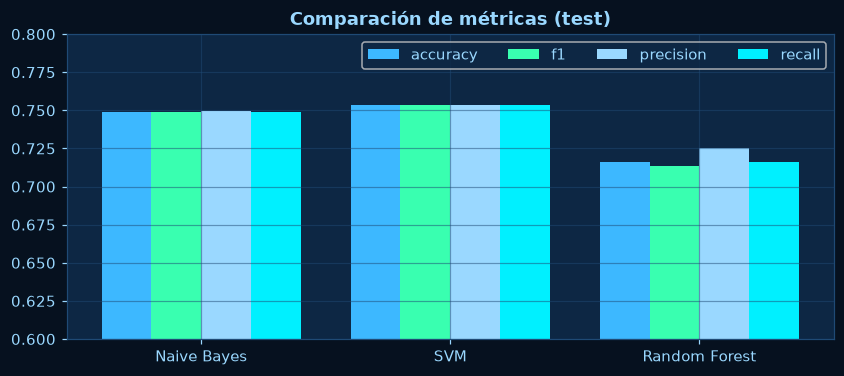

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(tabla)); w = .2
for i, (m, col) in enumerate(zip(["accuracy", "f1", "precision", "recall"], [ACENTO, POS, TINTA, "#00f0ff"])):
    ax.bar(x + (i - 1.5) * w, tabla[m], w, label=m, color=col)
ax.set_xticks(x, tabla.index); ax.set_ylim(.6, .8); ax.set_title("Comparación de métricas (test)"); ax.legend(ncol=4)
plt.show()

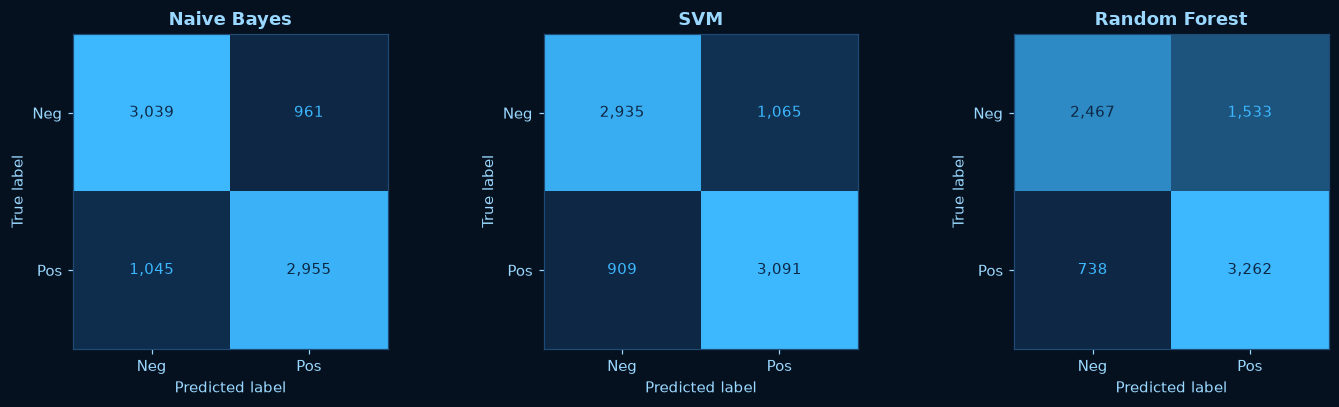

In [9]:
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("azul", ["#0d2744", "#3db8ff"])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (n, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["Neg", "Pos"]).plot(
        ax=ax, cmap=cmap, colorbar=False, values_format=",")
    ax.set_title(n); ax.grid(False)
plt.tight_layout(); plt.show()

In [10]:
votos = np.vstack(list(preds.values()))
acuerdo = (votos == votos[0]).all(0).mean()
consenso = (votos.sum(0) >= 2).astype(int)
print(f"Los 3 modelos coinciden en el {acuerdo:.1%} de los tweets de test")
print(f"Consenso por mayoría: accuracy={accuracy_score(y_test, consenso):.4f}  F1={f1_score(y_test, consenso, average='weighted'):.4f}")

Los 3 modelos coinciden en el 70.2% de los tweets de test
Consenso por mayoría: accuracy=0.7608  F1=0.7606


- **Naive Bayes y SVM empatan** (~75 %): con TF-IDF sobre texto corto, ambos modelos lineales funcionan muy bien.
- **Random Forest queda por debajo** y está **sesgado hacia "positivo"** (muchos falsos positivos en la matriz):
  los árboles con profundidad limitada sobre 5 000 features dispersas aprovechan peor la señal.
- El **consenso por mayoría** mejora alrededor de un punto sobre el mejor modelo individual.

## 5. Qué aprendió cada modelo

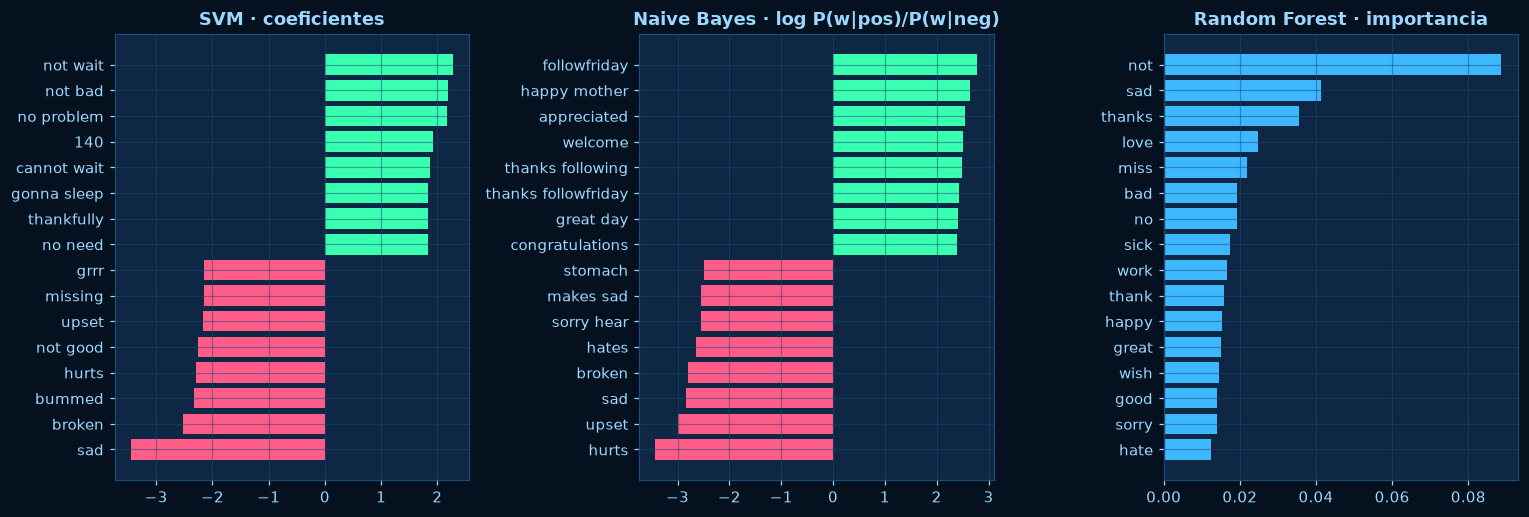

In [11]:
feats = np.array(vectorizer.get_feature_names_out())
coef = modelos["SVM"].coef_.ravel()
nb = modelos["Naive Bayes"]
nb_ratio = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
rf_imp = modelos["Random Forest"].feature_importances_

fig, ax = plt.subplots(1, 3, figsize=(14, 4.8))
for a, valores, titulo in [(ax[0], coef, "SVM · coeficientes"), (ax[1], nb_ratio, "Naive Bayes · log P(w|pos)/P(w|neg)")]:
    orden = np.argsort(valores); sel = np.r_[orden[:8], orden[-8:]]
    a.barh(feats[sel], valores[sel], color=[NEG if v < 0 else POS for v in valores[sel]]); a.set_title(titulo)
top_rf = np.argsort(rf_imp)[-16:]
ax[2].barh(feats[top_rf], rf_imp[top_rf], color=ACENTO); ax[2].set_title("Random Forest · importancia")
plt.tight_layout(); plt.show()

Los modelos lineales aprenden palabras con **dirección** (positiva o negativa). Random Forest solo da
**importancia** sin signo: las palabras más útiles para dividir los datos (`sad`, `thanks`, `miss`, …).

**Negaciones:** el preprocesamiento expande las contracciones (`don't` → `do not`) y conserva las
negaciones (`not`, `no`, `never`…) aunque sean *stop words*, para que bigramas como `not good` lleguen
al modelo. En la versión inicial se eliminaban; `src/analysis.py` mide el efecto de la corrección
(página *Análisis* de la app).

## 6. Generalización: test etiquetado a mano y percepción por marca

Sentiment140 incluye `testdata.manual.2009.06.14.csv`: ~500 tweets **etiquetados por personas** (no por
emoticonos) y agrupados por **consulta** (marcas y temas como `kindle2`, `nike`, `obama`…). Es la mejor
prueba de si los modelos sirven para medir la **percepción de marca**. Se descartan los neutrales (clase 2),
porque los modelos son binarios.

In [12]:
manual = pd.read_csv(RAW_DIR / "testdata.manual.2009.06.14.csv", encoding="latin-1", header=None, names=COLUMNS)
manual = manual[manual["target"] != 2].copy()
manual["label"] = (manual["target"] == 4).astype(int)
Xm = vectorizer.transform(manual["text"].map(limpiar_texto))

filas = []
for n, m in modelos.items():
    p = m.predict(Xm); manual[n] = p
    filas.append({"modelo": n, "accuracy": accuracy_score(manual.label, p), "f1": f1_score(manual.label, p, average="weighted")})
print(f"{len(manual)} tweets etiquetados a mano (sin neutrales)")
pd.DataFrame(filas).set_index("modelo").style.format("{:.3f}")

359 tweets etiquetados a mano (sin neutrales)


,accuracy,f1
modelo,,
Naive Bayes,0.811,0.811
SVM,0.788,0.788
Random Forest,0.699,0.690


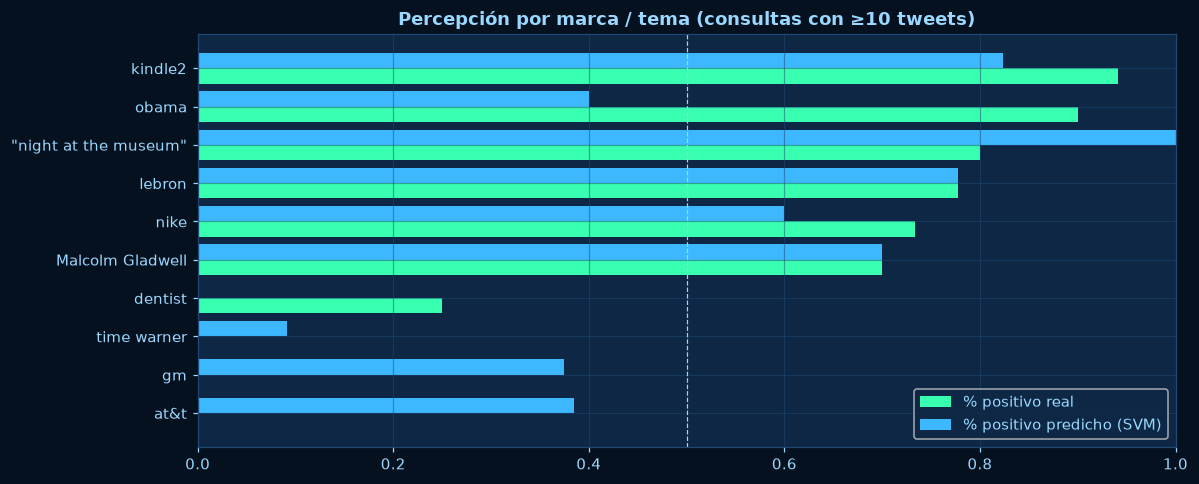

In [13]:
marcas = (manual.groupby("flag")
          .agg(n=("label", "size"), real=("label", "mean"), svm=("SVM", "mean"))
          .query("n >= 10").sort_values("real"))
fig, ax = plt.subplots(figsize=(11, 4.5))
y = np.arange(len(marcas))
ax.barh(y - .2, marcas["real"], .4, color=POS, label="% positivo real")
ax.barh(y + .2, marcas["svm"], .4, color=ACENTO, label="% positivo predicho (SVM)")
ax.set_yticks(y, marcas.index); ax.set_xlim(0, 1); ax.axvline(.5, color=TINTA, ls="--", lw=.8)
ax.set_title("Percepción por marca / tema (consultas con ≥10 tweets)"); ax.legend()
plt.tight_layout(); plt.show()

## 7. Conclusiones

1. **Preprocesamiento + TF-IDF** (uni/bigramas) es suficiente para una línea base sólida en tweets.
2. **Naive Bayes ≈ SVM ≈ 75 %** de accuracy y F1; **Random Forest ≈ 71 %** y sesgado hacia positivo.
   Para producción se elegiría **SVM o Naive Bayes** (más precisos, rápidos y ligeros).
3. En el **test etiquetado a mano** los modelos generalizan bien (NB ≈ 81 %, SVM ≈ 79 %; mejor que en el
   test ruidoso), y el % positivo predicho por marca sigue la tendencia del real: sirven para **comparar
   percepción de marca**, aunque con errores en marcas con pocos tweets.
4. **Limitaciones:** etiquetas ruidosas (emoticonos), sin clase neutral, solo inglés y tweets de 2009;
   la distribución temporal del dataset está sesgada por la forma de recolección.